In [85]:
import inspect
import importlib
import pkgutil
import pymoo.algorithms.moo as moo
import pymoo
import numpy as np
import pandas as pd
import time
from greyhaven_problem import GreyhavenProblem
from pymoo.core.problem import ElementwiseProblem
from pymoo.core.variable import Real, Integer, Choice, Binary
from pymoo.core.mixed import (
    MixedVariableMating,
    MixedVariableSampling,
    MixedVariableDuplicateElimination
)
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV
import matplotlib.pyplot as plt
import seaborn as sns

In [160]:
import greyhaven_problem
import importlib

importlib.reload(greyhaven_problem)

from greyhaven_problem import GreyhavenProblem

In [60]:
from pymoo.algorithms.moo.age import AGEMOEA
from pymoo.algorithms.moo.cmopso import CMOPSO
from pymoo.algorithms.moo.ctaea import CTAEA
from pymoo.algorithms.moo.dnsga2 import DNSGA2
from pymoo.algorithms.moo.gde3 import GDE3, GDE32NN, GDE3MNN, GDE3PCD
from pymoo.algorithms.moo.kgb import KGB
from pymoo.algorithms.moo.moead import MOEAD
from pymoo.algorithms.moo.mopso_cd import MOPSO_CD
from pymoo.algorithms.moo.nsde import NSDE
from pymoo.algorithms.moo.nsder import NSDER
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.moo.pinsga2 import PINSGA2
from pymoo.algorithms.moo.rnsga2 import RNSGA2
from pymoo.algorithms.moo.rnsga3 import RNSGA3
from pymoo.algorithms.moo.rvea import RVEA
from pymoo.algorithms.moo.sms import SMSEMOA
from pymoo.algorithms.moo.spea2 import SPEA2
from pymoo.algorithms.moo.unsga3 import UNSGA3


algorithms = {
    "AGEMOEA": AGEMOEA,
    "CMOPSO": CMOPSO,
    "CTAEA": CTAEA,
    "DNSGA2": DNSGA2,
    "GDE3": GDE3,
    "GDE32NN": GDE32NN,
    "GDE3MNN": GDE3MNN,
    "GDE3PCD": GDE3PCD,
    "KGB": KGB,
    "MOEAD": MOEAD,
    "MOPSO_CD": MOPSO_CD,
    "NSDE": NSDE,
    "NSDER": NSDER,
    "NSGA2": NSGA2,
    "NSGA3": NSGA3,
    "PINSGA2": PINSGA2,
    "RNSGA2": RNSGA2,
    "RNSGA3": RNSGA3,
    "RVEA": RVEA,
    "SMSEMOA": SMSEMOA,
    "SPEA2": SPEA2,
    "UNSGA3": UNSGA3
}

In [61]:
class GreyhavenMOOProblem(ElementwiseProblem):

    def __init__(self, situation):

        self.gh = GreyhavenProblem(
            situation=situation,
            assignment="C"
        )

        variables = {}

        for i in range(4):
            variables[f"x{i}"] = Real(bounds=(0, 10))
            variables[f"y{i}"] = Real(bounds=(0, 10))
            variables[f"p{i}"] = Real(bounds=(0.2, 2))
            variables[f"h{i}"] = Integer(bounds=(2, 6))
            variables[f"c{i}"] = Choice(options=[1, 2, 3])
            variables[f"z{i}"] = Binary()

        super().__init__(
            vars=variables,
            n_obj=3
        )

    def decode_stations(self, X):

        stations = []

        for i in range(4):
            stations.append([
                X[f"x{i}"],
                X[f"y{i}"],
                X[f"p{i}"],
                X[f"h{i}"],
                X[f"c{i}"],
                X[f"z{i}"]
            ])

        return np.asarray(stations, dtype=float)

    def _evaluate(self, X, out, *args, **kwargs):

        stations = self.decode_stations(X)

        out["F"] = self.gh.calculate_objectives(stations)

def get_mixed_options():

    duplicate_elimination = MixedVariableDuplicateElimination()

    return {
        "sampling": MixedVariableSampling(),
        "mating": MixedVariableMating(
            eliminate_duplicates=duplicate_elimination
        ),
        "eliminate_duplicates": duplicate_elimination
    }

def create_model(name, optimizer):
    options = get_mixed_options()

    if name == "NSGA3":
        ref_dirs = get_reference_directions(
            "das-dennis", 3, n_partitions=12
        )
        return NSGA3(
            ref_dirs=ref_dirs,
            pop_size=len(ref_dirs),
            **options
        )

    else:
        model = optimizer(
            pop_size=50,
            **options
        )

    return model

In [150]:
def run_experiment(situation, model, n_runs=31, pop_size=50, max_fe=10000):

    results = []
    convergence = []
    runtimes = []
    solutions = []

    actual_budget = (max_fe // pop_size) * pop_size

    print(f"\nAlgorithm: {model}")
    print(f"Situation: {situation}")
    print(f"Runs: {n_runs}")
    print(f"Maximum FE budget: {actual_budget}")

    for run in range(n_runs):

        seed = run + 1
        problem = GreyhavenMOOProblem(situation)

        start = time.time()

        result = minimize(
            problem,
            model,
            termination=("n_eval", actual_budget),
            seed=seed,
            verbose=False,
            save_history=True
        )

        runtime = time.time() - start

        F = result.opt.get("F")
        X = list(result.opt.get("X"))

        results.append(F)
        solutions.append(X)

        run_convergence = []

        for history_item in result.history:
            run_convergence.append(history_item.pop.get("F"))

        convergence.append(run_convergence)
        runtimes.append(runtime)

        epochs = len(result.history)

        print(
            f"\nRun {run + 1}/{n_runs} | "
            f"Pareto solutions: {len(F)} | "
            f"Epochs: {epochs} | "
            f"Time: {runtime:.2f}s"
        )

    return results, convergence, np.array(runtimes), solutions

In [63]:
def calculate_hv(F, ref_point):
    F = np.asarray(F)

    if F.size == 0:
        return 0.0

    F = F[np.all(np.isfinite(F), axis=1)]

    if len(F) == 0:
        return 0.0

    return HV(ref_point=ref_point)(F)

In [89]:
def calculate_hv_convergence(all_results, ref_point):
    hv_results = {}

    for name, (results, convergence, runtimes, solutions) in all_results.items():

        run_hv = []

        for run in convergence:
            generation_hv = [
                calculate_hv(F, ref_point)
                for F in run
            ]

            run_hv.append(generation_hv)

        hv_results[name] = run_hv

    return hv_results

In [65]:
def plot_hv_convergence(hv_results):

    plt.figure(figsize=(10, 6))

    for name, runs in hv_results.items():

        max_len = max(len(run) for run in runs)

        values = np.full((len(runs), max_len), np.nan)

        for i, run in enumerate(runs):
            values[i, :len(run)] = run

        mean = np.nanmean(values, axis=0)
        std = np.nanstd(values, axis=0)

        generations = np.arange(1, max_len + 1)

        plt.plot(generations, mean, label=name)
        plt.fill_between(
            generations,
            mean - std,
            mean + std,
            alpha=0.15
        )

    plt.xlabel("Generation")
    plt.ylabel("Hypervolume (HV)")
    plt.title("Hypervolume Convergence")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [66]:
def plot_hv_boxplot(hv_results):

    data = []
    labels = []

    for name, runs in hv_results.items():
        final_values = [run[-1] for run in runs if len(run) > 0]

        data.append(final_values)
        labels.append(name)

    plt.figure(figsize=(9, 6))

    plt.boxplot(data, tick_labels=labels, showmeans=True)

    plt.ylabel("Final Hypervolume (HV)")
    plt.title("Final Hypervolume Comparison")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [90]:
def plot_runtime_boxplot(all_results):

    data = [
        runtimes
        for _, (_, _, runtimes, _) in all_results.items()
    ]

    labels = list(all_results.keys())

    plt.figure(figsize=(9, 6))

    plt.boxplot(data, tick_labels=labels, showmeans=True)

    plt.ylabel("Runtime (seconds)")
    plt.title("Runtime Comparison")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [91]:
def plot_pareto_fronts(all_results):

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    for name, (results, _, _, _) in all_results.items():

        F = np.vstack(results)

        ax.scatter(
            F[:, 0],
            F[:, 1],
            F[:, 2],
            label=name,
            alpha=0.65,
            s=35
        )

    ax.set_xlabel("Q")
    ax.set_ylabel("C")
    ax.set_zlabel("E")

    ax.set_title("Final Pareto Front Comparison")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [92]:
def plot_best_pareto_fronts(all_results, hv_results):

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    for name, (results, _, _, _) in all_results.items():

        best_run = np.argmax([
            run[-1] for run in hv_results[name]
        ])

        F = results[best_run]

        ax.scatter(
            F[:, 0],
            F[:, 1],
            F[:, 2],
            label=name,
            alpha=0.7,
            s=40
        )

    ax.set_xlabel("Q")
    ax.set_ylabel("C")
    ax.set_zlabel("E")

    ax.set_title("Best-Run Pareto Front Comparison")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [161]:
def best_solutions(all_results, situation):

    rows = []

    problem = GreyhavenProblem(
        situation=situation,
        assignment="B"
    )

    for name, (results, _, _, solutions) in all_results.items():

        best_F = None
        best_X = None
        best_score = np.inf

        for F, X in zip(results, solutions):

            F = np.atleast_2d(F)

            f_min = F.min(axis=0)
            f_max = F.max(axis=0)
            normalized = (F - f_min) / (f_max - f_min + 1e-12)

            scores = np.linalg.norm(normalized, axis=1)
            idx = np.argmin(scores)

            if scores[idx] < best_score:
                best_score = scores[idx]
                best_F = F[idx]
                best_X = X[idx]

        stations = np.array([
            [best_X[f"{v}{i}"] for v in ["x", "y", "p", "h", "c", "z"]]
            for i in range(4)
        ], dtype=float)

        row = {
            "Algorithm": name,
            "Q": best_F[0],
            "C": best_F[1],
            "E": best_F[2]
        }

        for i in range(4):
            for j, v in enumerate(["x", "y", "p", "h", "c", "z"]):
                row[f"{v}{i}"] = stations[i, j]

        rows.append(row)

        print(f"\n{name} | Q={best_F[0]:.4f}, C={best_F[1]:.4f}, E={best_F[2]:.4f}")
        problem.plot_deployment(stations)

    return pd.DataFrame(rows)

In [113]:
def summarize_results(all_results, hv_results):

    rows = []

    for name, (results, convergence, runtimes, solutions) in all_results.items():

        final_hv = np.array([
            run[-1] for run in hv_results[name]
        ])

        pareto_counts = [
            len(F) for F in results
        ]

        rows.append({
            "Algorithm": name,
            "Mean HV": np.mean(final_hv),
            "Std HV": np.std(final_hv, ddof=1),
            "Best HV": np.max(final_hv),
            "Worst HV": np.min(final_hv),
            "Mean Pareto Solutions": np.mean(pareto_counts),
            "Mean Runtime (s)": np.mean(runtimes),
            "Std Runtime (s)": np.std(runtimes, ddof=1)
        })

    return pd.DataFrame(rows).sort_values(
        "Mean HV", ascending=False
    ).reset_index(drop=True)

## Initial response

In [163]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["NSGA2", "NSGA3", "SPEA2"]
}
for name, optimizer in selected_algorithms.items():
    model = create_model(name, optimizer)
    print(f"\n========== {name} ==========")
    all_results[name] = run_experiment(
        "Initial response",
        model
    )


========== NSGA2 ==========

Algorithm: <pymoo.algorithms.moo.nsga2.NSGA2 object at 0x000001BA153B7260>
Situation: Initial response
Runs: 31
Maximum FE budget: 10000

Run 1/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.48s

Run 2/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.51s

Run 3/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.25s

Run 4/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.72s

Run 5/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.01s

Run 6/31 | Pareto solutions: 50 | Epochs: 200 | Time: 9.13s

Run 7/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.07s

Run 8/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.12s

Run 9/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.18s

Run 10/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.98s

Run 11/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.17s

Run 12/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.08s

Run 13/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.84s

Run 14/31 | Pareto solutions: 50 | 

In [164]:
all_F = np.vstack([
    F
    for name in all_results
    for run in all_results[name][0]
    for F in run
])

print("Objective minimum:", all_F.min(axis=0))
print("Objective maximum:", all_F.max(axis=0))

ref_point = all_F.max(axis=0) + 0.1 * (
    all_F.max(axis=0) - all_F.min(axis=0)
)

hv_results = calculate_hv_convergence(
    all_results,
    ref_point
)

Objective minimum: [-0.99307812  0.          0.        ]
Objective maximum: [  -0.         3782.94737738 2031.2635394 ]


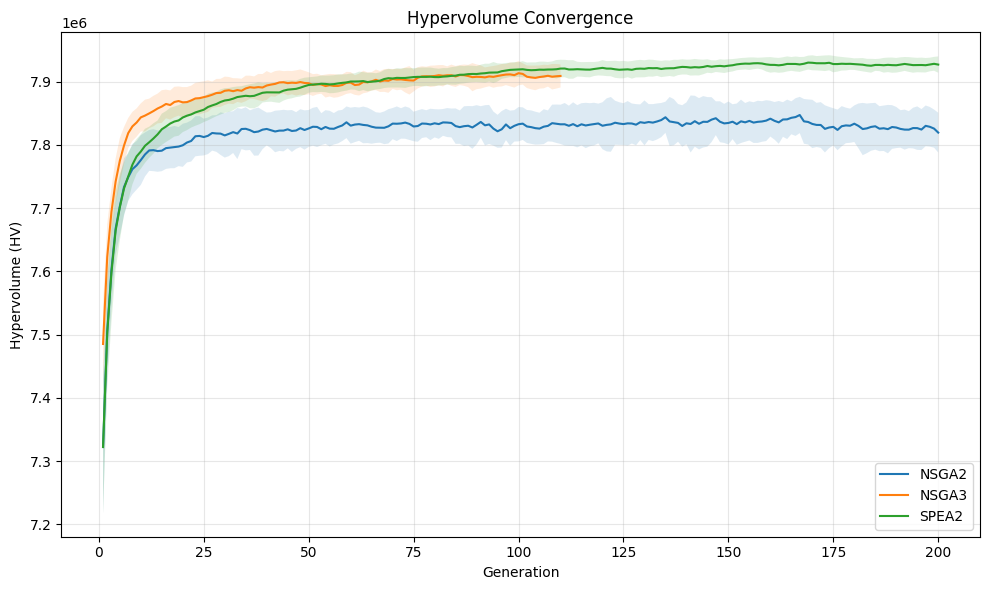

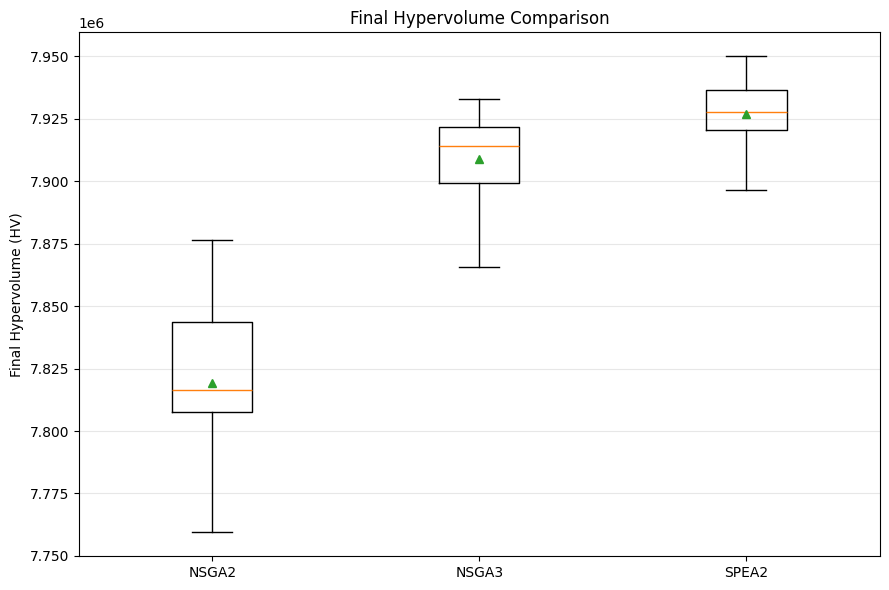

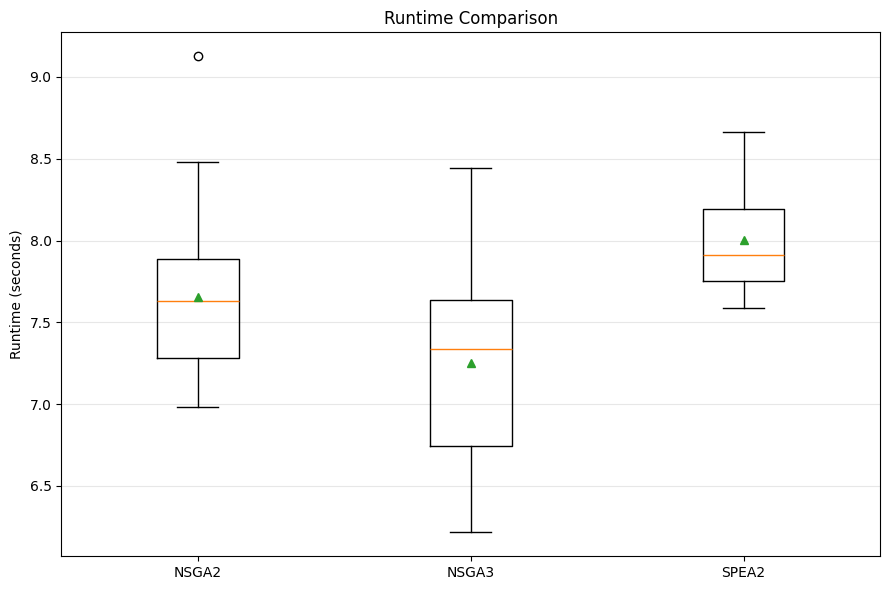

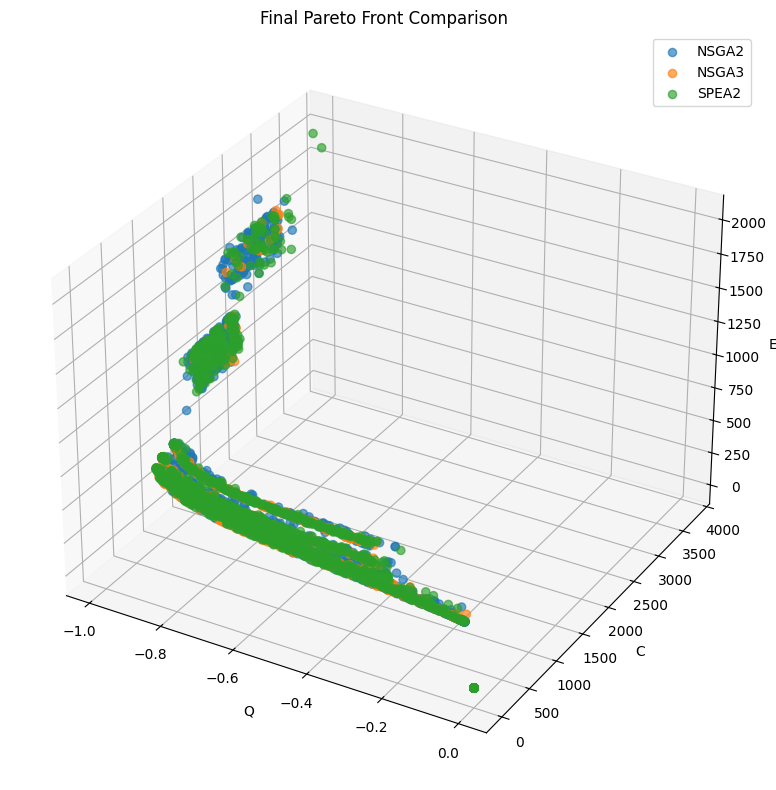

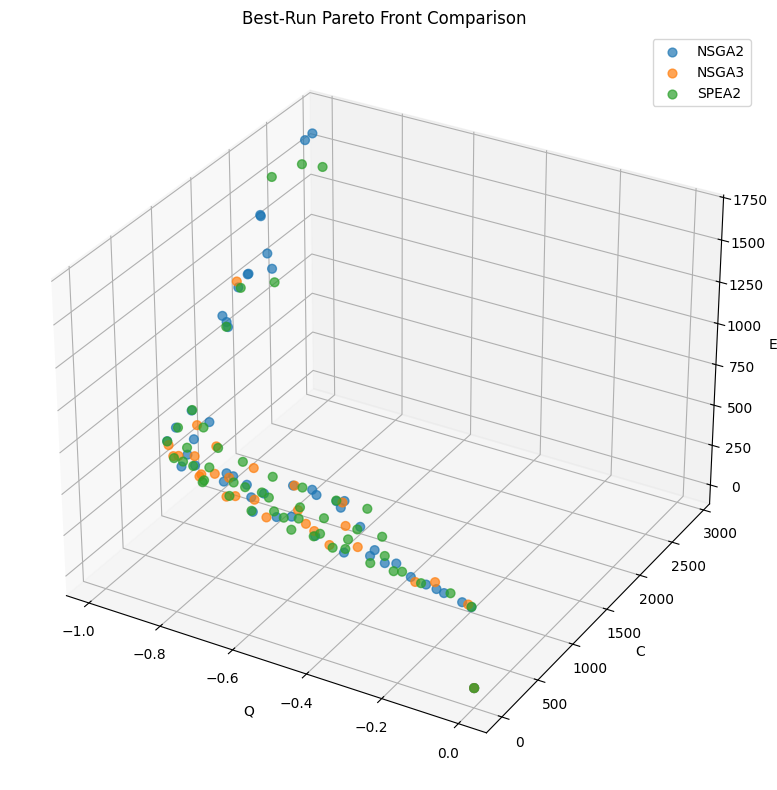

In [165]:
plot_hv_convergence(hv_results)
plot_hv_boxplot(hv_results)
plot_runtime_boxplot(all_results)
plot_pareto_fronts(all_results)
plot_best_pareto_fronts(all_results, hv_results)

In [166]:
summary = summarize_results(all_results, hv_results)
display(summary.round(4))

,Algorithm,Mean HV,Std HV,Best HV,Worst HV,Mean Pareto Solutions,Mean Runtime (s),Std Runtime (s)
0,SPEA2,7.926949e+06,13086.9459,7.950094e+06,7.896643e+06,50.0000,8.0037,0.3256
1,NSGA3,7.908956e+06,18513.8859,7.932923e+06,7.865586e+06,28.8065,7.2509,0.5939
2,NSGA2,7.819410e+06,31939.7812,7.876384e+06,7.759399e+06,50.0000,7.6572,0.4677


In [167]:
summary.to_excel(
    f"results/C_Initial_response_summary.xlsx",
    index=False
)


NSGA2 | Q=-0.8936, C=521.2351, E=483.8487


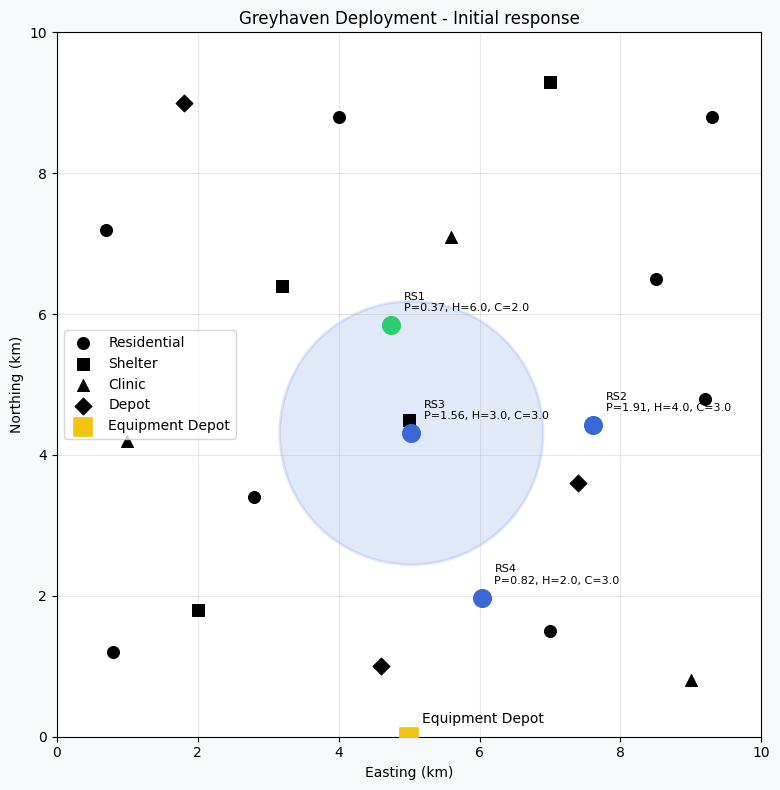


NSGA3 | Q=-0.8437, C=604.7509, E=408.3601


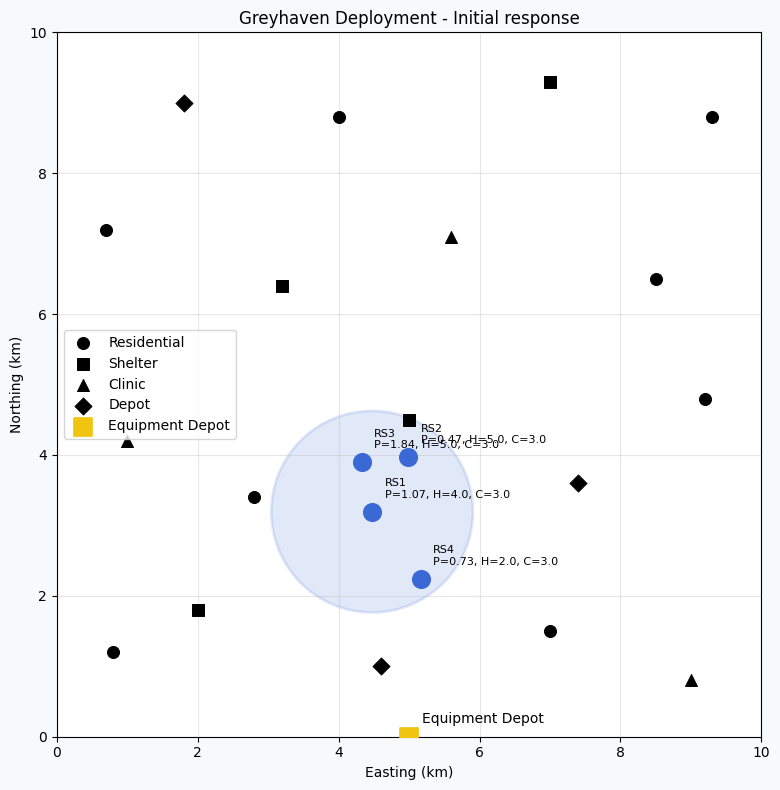


SPEA2 | Q=-0.8774, C=624.1268, E=414.7045


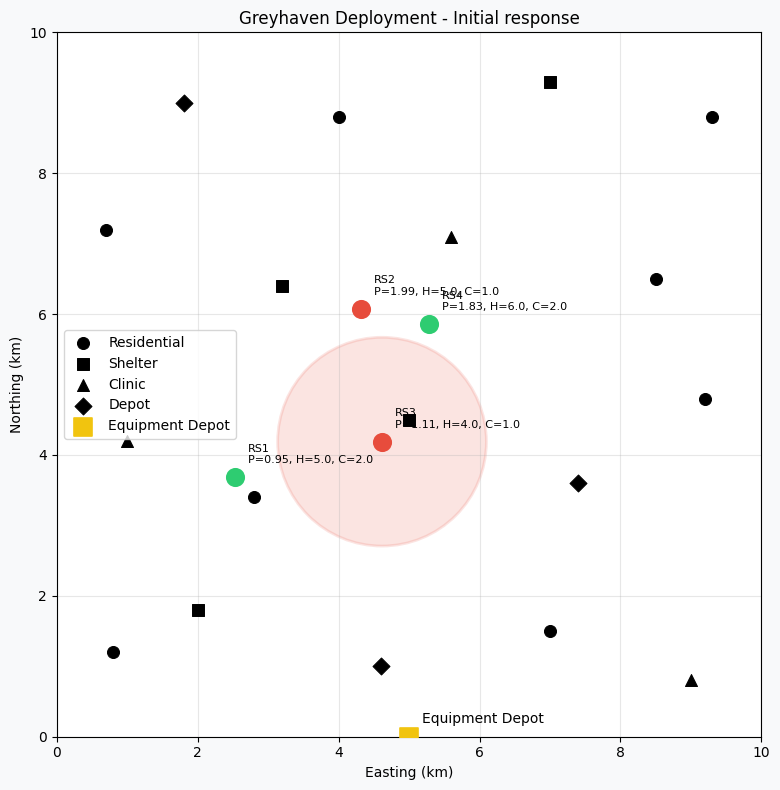

,Algorithm,Q,C,E,x0,y0,p0,h0,c0,z0,...,p2,h2,c2,z2,x3,y3,p3,h3,c3,z3
0,NSGA2,-0.893641,521.235087,483.848672,4.747264,5.843260,0.374337,6.0,2.0,0.0,...,1.558623,3.0,3.0,1.0,6.034780,1.975793,0.822209,2.0,3.0,0.0
1,NSGA3,-0.843728,604.750935,408.360060,4.474815,3.194666,1.073572,4.0,3.0,1.0,...,1.843221,5.0,3.0,0.0,5.167112,2.246043,0.734317,2.0,3.0,0.0
2,SPEA2,-0.877392,624.126813,414.704514,2.533245,3.685758,0.945350,5.0,2.0,0.0,...,1.111336,4.0,1.0,1.0,5.284970,5.855538,1.832864,6.0,2.0,0.0


In [168]:
best_table = best_solutions(all_results, "Initial response")
display(best_table)
best_table.to_excel(f"results/C_best_solutions_initial_response.xlsx", index=False)

## Evening pressure

In [170]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["NSGA2", "NSGA3", "SPEA2"]
}
for name, optimizer in selected_algorithms.items():
    print(f"\n========== {name} ==========")
    model = create_model(name, optimizer)
    all_results[name] = run_experiment(
        "Evening pressure",
        model
    )


========== NSGA2 ==========

Algorithm: <pymoo.algorithms.moo.nsga2.NSGA2 object at 0x000001BA0DA84530>
Situation: Evening pressure
Runs: 31
Maximum FE budget: 10000

Run 1/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.45s

Run 2/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.33s

Run 3/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.80s

Run 4/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.56s

Run 5/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.58s

Run 6/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.72s

Run 7/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.53s

Run 8/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.44s

Run 9/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.86s

Run 10/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.70s

Run 11/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.77s

Run 12/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.60s

Run 13/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.77s

Run 14/31 | Pareto solutions: 50 | 

In [171]:
all_F = np.vstack([
    F
    for name in all_results
    for run in all_results[name][0]
    for F in run
])

print("Objective minimum:", all_F.min(axis=0))
print("Objective maximum:", all_F.max(axis=0))

ref_point = all_F.max(axis=0) + 0.1 * (
    all_F.max(axis=0) - all_F.min(axis=0)
)

hv_results = calculate_hv_convergence(
    all_results,
    ref_point
)

Objective minimum: [-0.98725047  0.          0.        ]
Objective maximum: [  -0.         3749.90184277 1949.53840757]


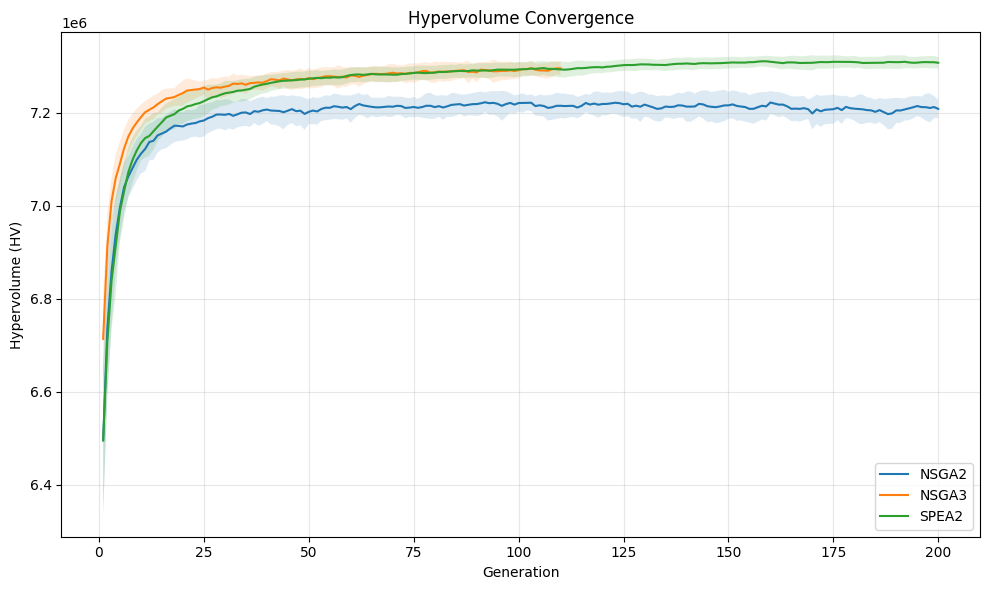

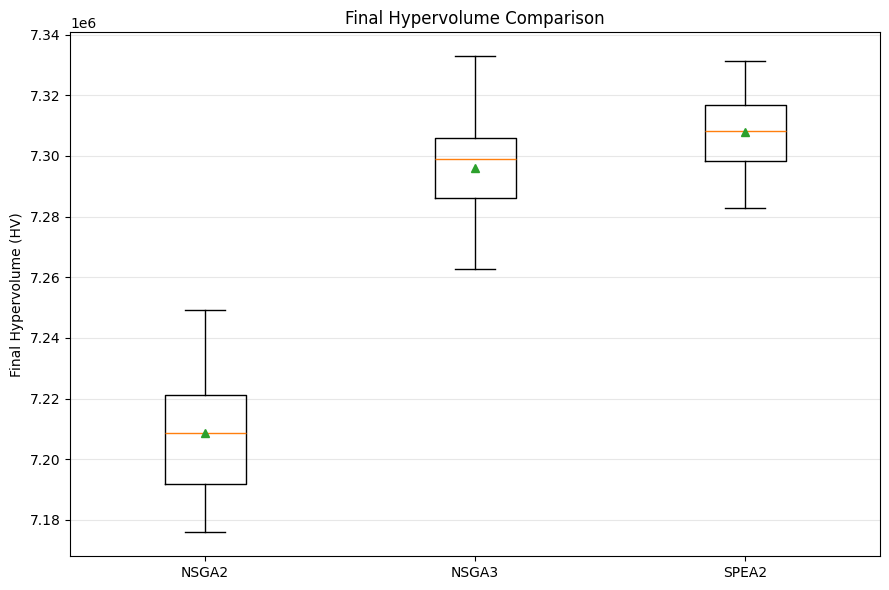

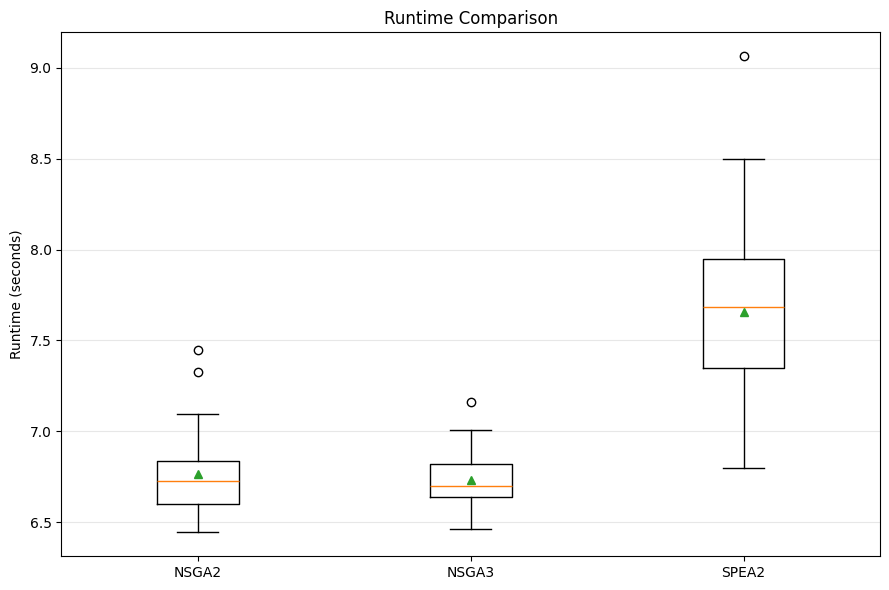

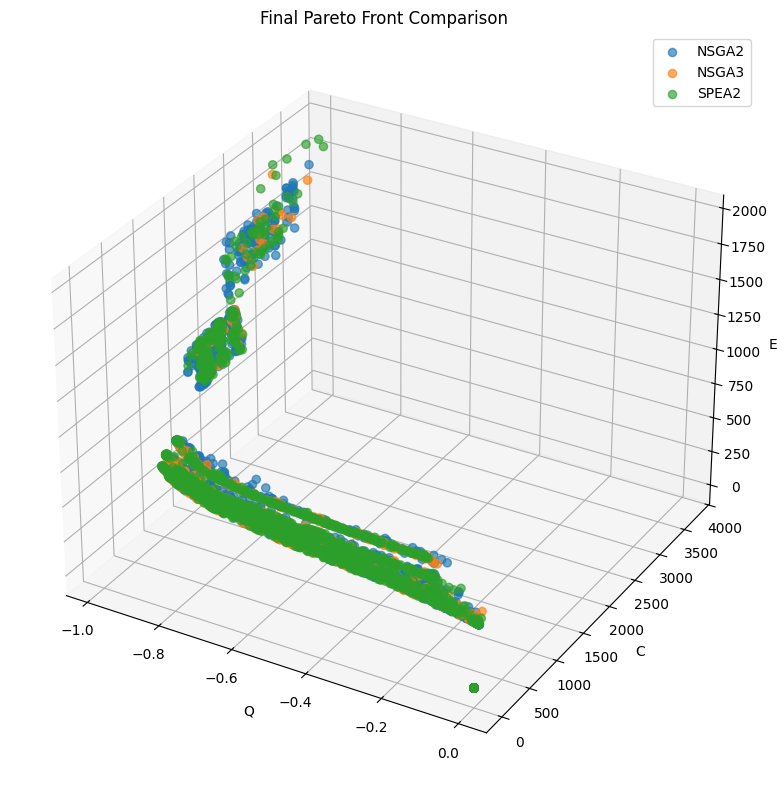

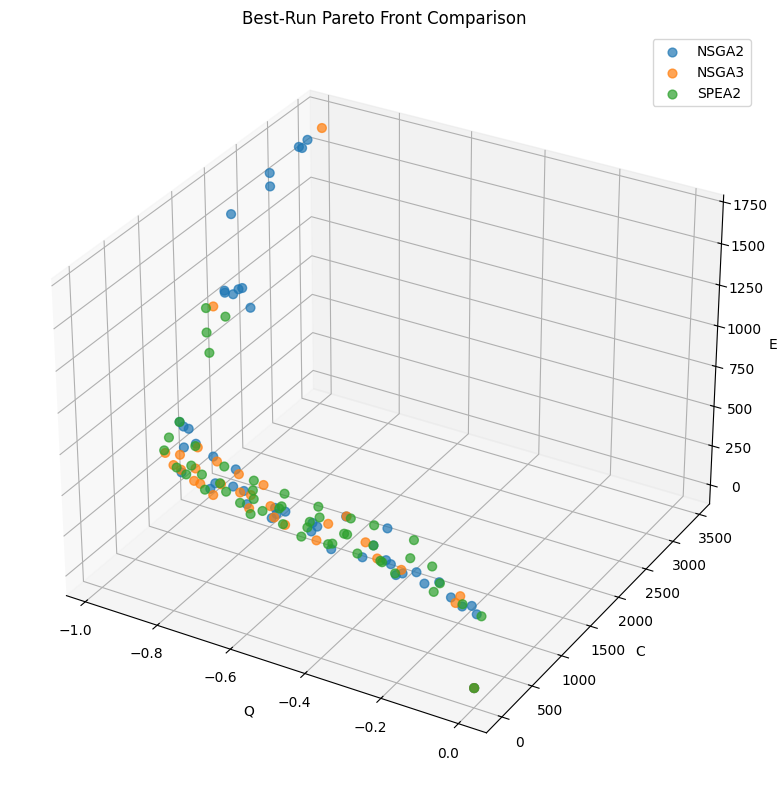

In [172]:
plot_hv_convergence(hv_results)
plot_hv_boxplot(hv_results)
plot_runtime_boxplot(all_results)
plot_pareto_fronts(all_results)
plot_best_pareto_fronts(all_results, hv_results)

In [173]:
summary = summarize_results(all_results, hv_results)
display(summary.round(4))
summary.to_excel(
    f"results/C_Initial_response_summary.xlsx",
    index=False
)

,Algorithm,Mean HV,Std HV,Best HV,Worst HV,Mean Pareto Solutions,Mean Runtime (s),Std Runtime (s)
0,SPEA2,7.307912e+06,12314.0613,7.331218e+06,7.282715e+06,50.0000,7.6593,0.4829
1,NSGA3,7.295965e+06,15586.0612,7.332927e+06,7.262693e+06,28.2903,6.7303,0.1587
2,NSGA2,7.208766e+06,19446.3712,7.249341e+06,7.175812e+06,50.0000,6.7651,0.2210



NSGA2 | Q=-0.8599, C=626.6363, E=448.0790


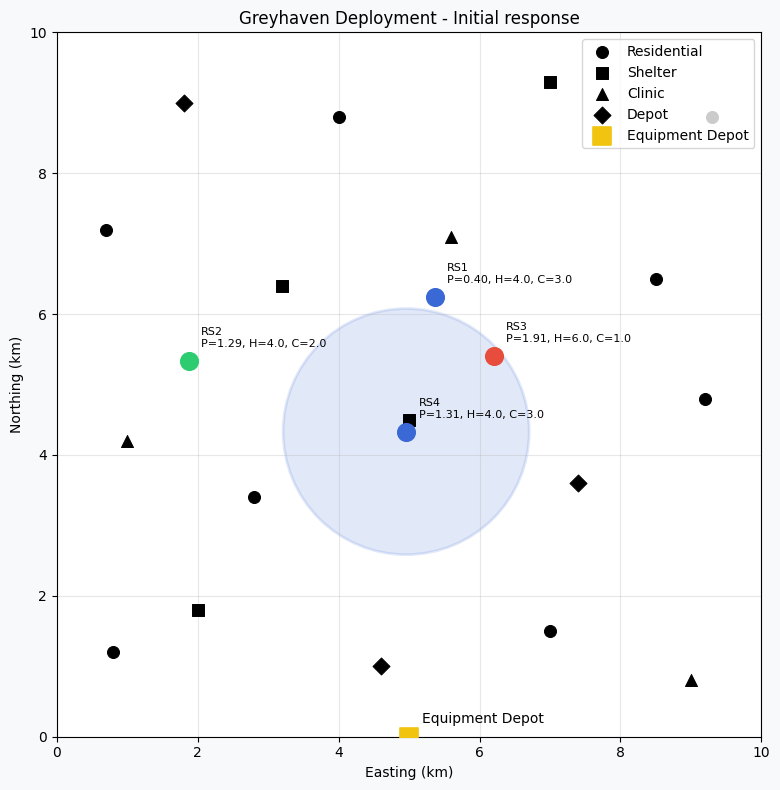


NSGA3 | Q=-0.8261, C=537.7133, E=459.5193


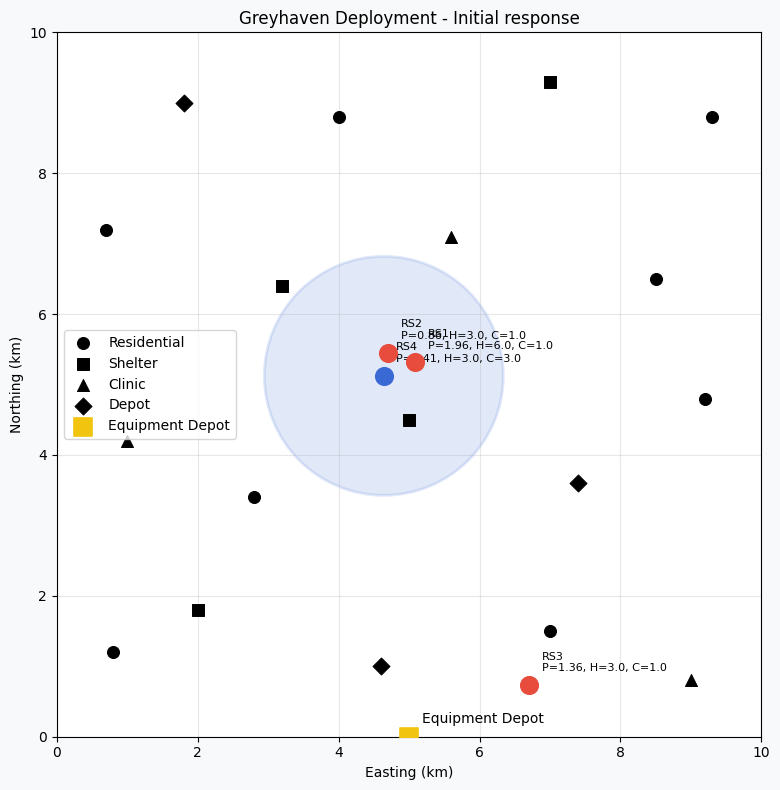


SPEA2 | Q=-0.8478, C=636.4111, E=429.1611


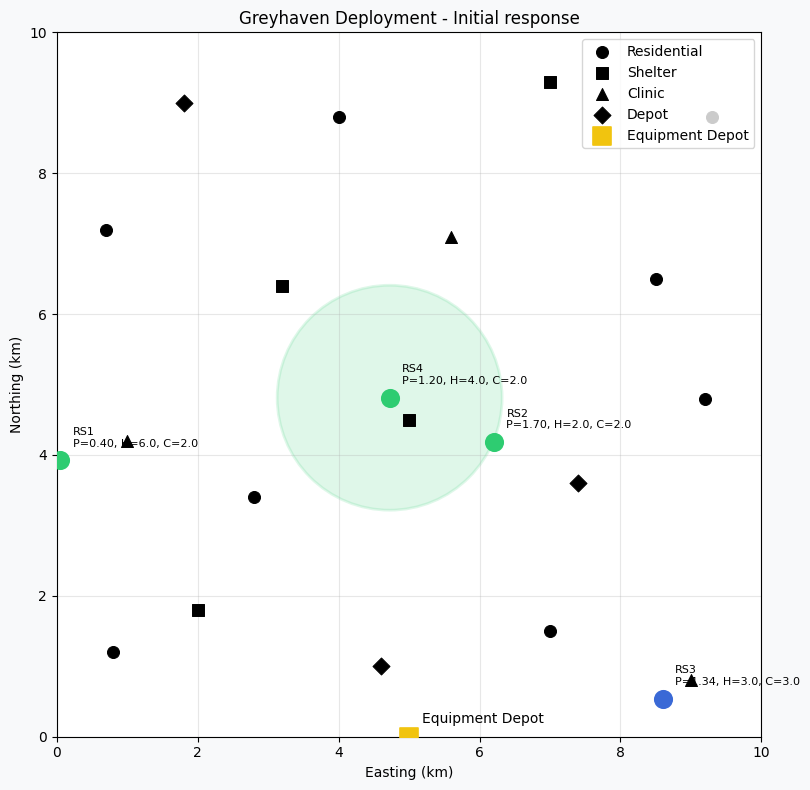

,Algorithm,Q,C,E,x0,y0,p0,h0,c0,z0,...,p2,h2,c2,z2,x3,y3,p3,h3,c3,z3
0,NSGA2,-0.859883,626.636254,448.078964,5.365403,6.246543,0.401131,4.0,3.0,0.0,...,1.910321,6.0,1.0,0.0,4.958045,4.331610,1.309994,4.0,3.0,1.0
1,NSGA3,-0.826123,537.713334,459.519298,5.089938,5.313479,1.961461,6.0,1.0,0.0,...,1.364395,3.0,1.0,0.0,4.641049,5.123107,1.413805,3.0,3.0,1.0
2,SPEA2,-0.847825,636.411111,429.161056,0.051001,3.922141,0.396553,6.0,2.0,0.0,...,1.338239,3.0,3.0,0.0,4.723727,4.812632,1.197387,4.0,2.0,1.0


In [174]:
best_table = best_solutions(all_results, "Initial response")
display(best_table)
best_table.to_excel(f"results/C_best_solutions_initial_response.xlsx", index=False)

## Northern outage

In [175]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["NSGA2", "NSGA3", "SPEA2"]
}
for name, optimizer in selected_algorithms.items():
    print(f"\n========== {name} ==========")
    model = create_model(name, optimizer)
    all_results[name] = run_experiment(
        "Northern outage",
        model
    )


========== NSGA2 ==========

Algorithm: <pymoo.algorithms.moo.nsga2.NSGA2 object at 0x000001BA0DA87230>
Situation: Northern outage
Runs: 31
Maximum FE budget: 10000

Run 1/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.61s

Run 2/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.13s

Run 3/31 | Pareto solutions: 50 | Epochs: 200 | Time: 8.08s

Run 4/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.38s

Run 5/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.16s

Run 6/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.68s

Run 7/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.77s

Run 8/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.42s

Run 9/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.40s

Run 10/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.39s

Run 11/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.73s

Run 12/31 | Pareto solutions: 50 | Epochs: 200 | Time: 7.00s

Run 13/31 | Pareto solutions: 50 | Epochs: 200 | Time: 6.49s

Run 14/31 | Pareto solutions: 50 | E

In [176]:
all_F = np.vstack([
    F
    for name in all_results
    for run in all_results[name][0]
    for F in run
])

print("Objective minimum:", all_F.min(axis=0))
print("Objective maximum:", all_F.max(axis=0))

ref_point = all_F.max(axis=0) + 0.1 * (
    all_F.max(axis=0) - all_F.min(axis=0)
)

hv_results = calculate_hv_convergence(
    all_results,
    ref_point
)

Objective minimum: [-0.97557174  0.          0.        ]
Objective maximum: [  -0.         3798.07402455 2059.86712071]


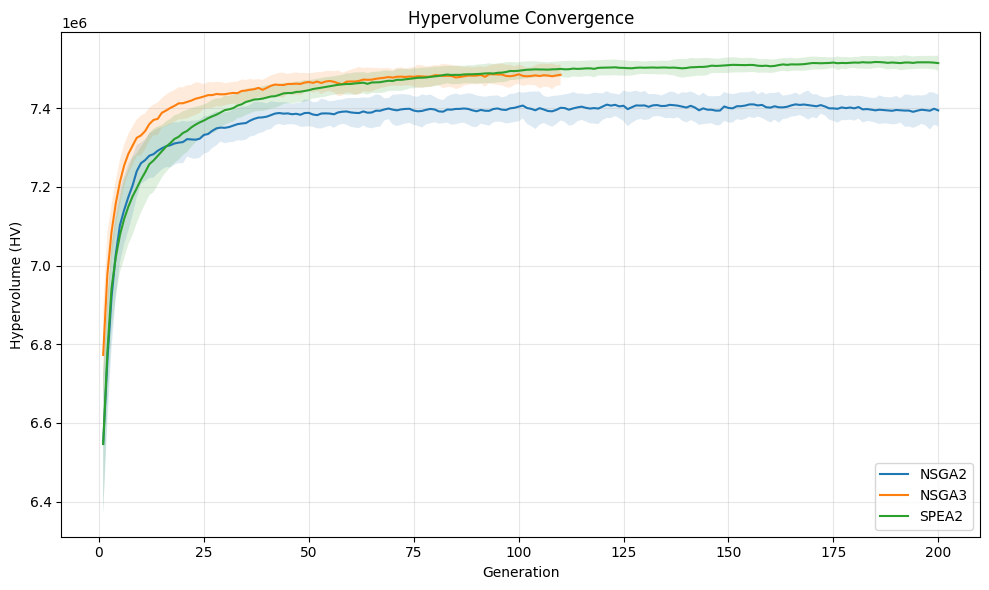

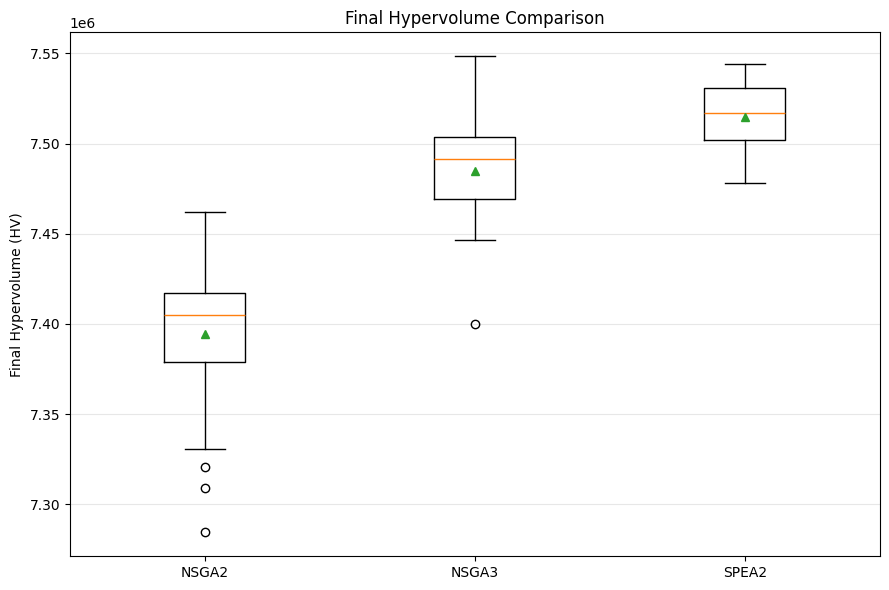

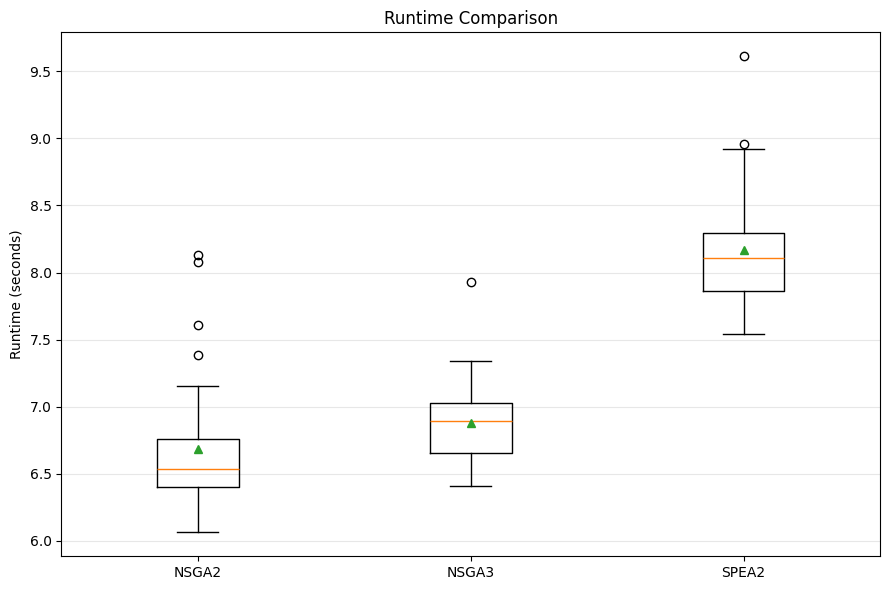

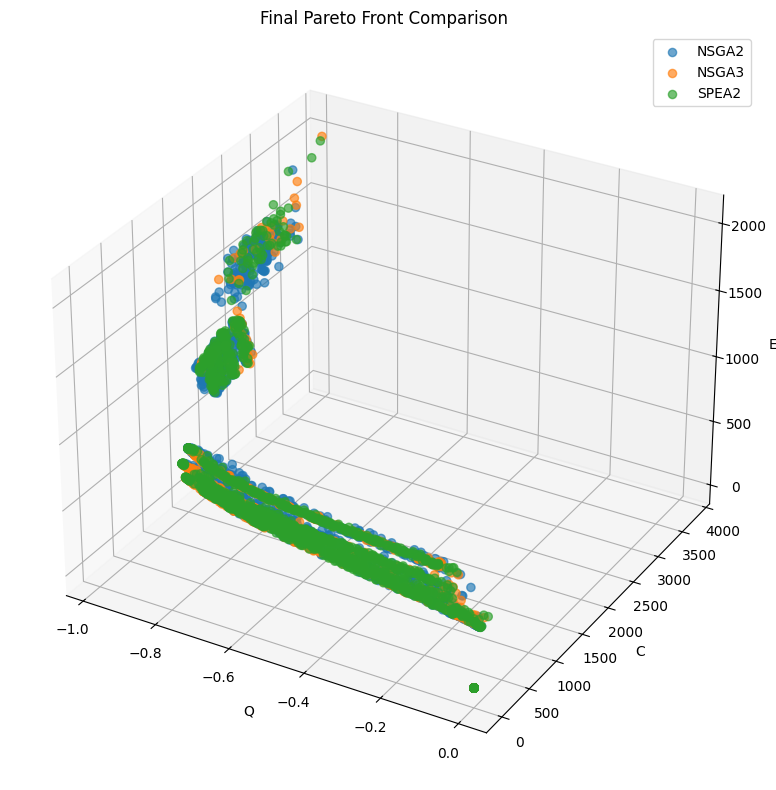

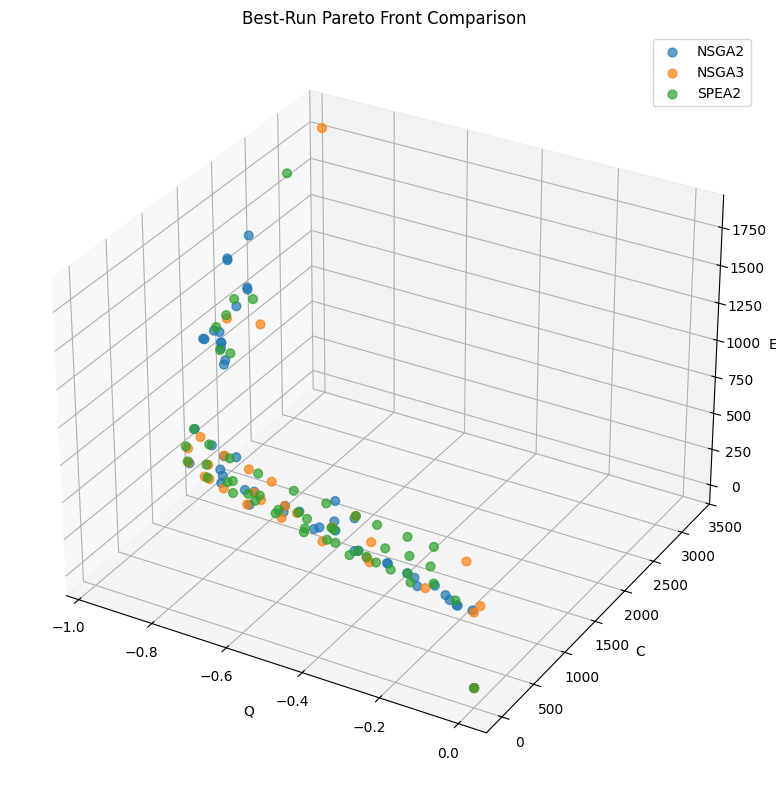

In [177]:
plot_hv_convergence(hv_results)
plot_hv_boxplot(hv_results)
plot_runtime_boxplot(all_results)
plot_pareto_fronts(all_results)
plot_best_pareto_fronts(all_results, hv_results)

In [178]:
summary = summarize_results(all_results, hv_results)
display(summary.round(4))
summary.to_excel(
    f"results/C_Initial_response_summary.xlsx",
    index=False
)

,Algorithm,Mean HV,Std HV,Best HV,Worst HV,Mean Pareto Solutions,Mean Runtime (s),Std Runtime (s)
0,SPEA2,7.514718e+06,19205.5349,7.544233e+06,7.477967e+06,50.0000,8.1665,0.4681
1,NSGA3,7.484974e+06,27437.3744,7.548444e+06,7.400152e+06,27.2258,6.8758,0.3019
2,NSGA2,7.394383e+06,40994.7772,7.461787e+06,7.284410e+06,50.0000,6.6868,0.5071



NSGA2 | Q=-0.7289, C=533.2439, E=515.6955


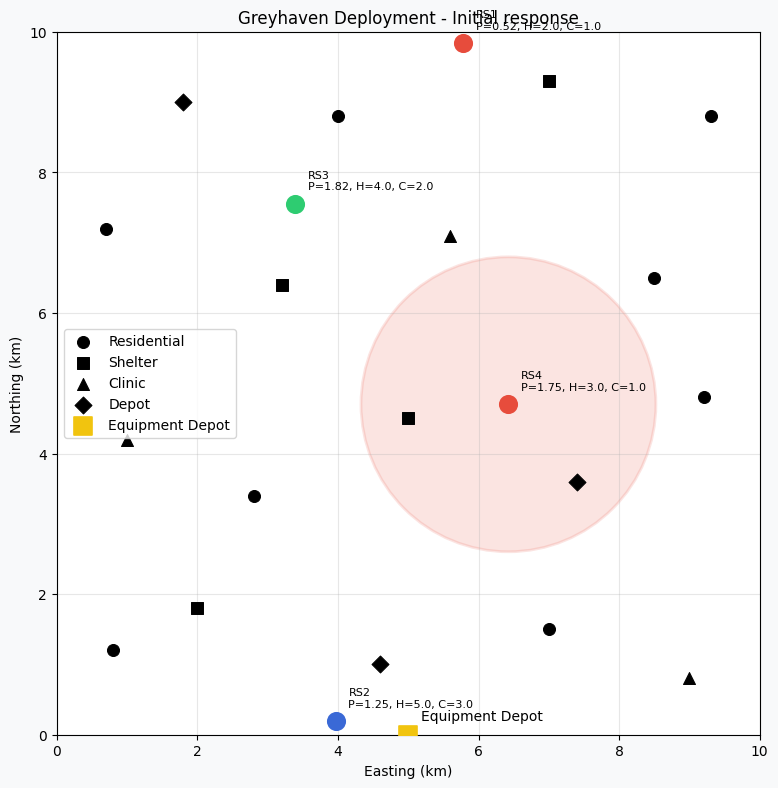


NSGA3 | Q=-0.8151, C=652.0605, E=504.5324


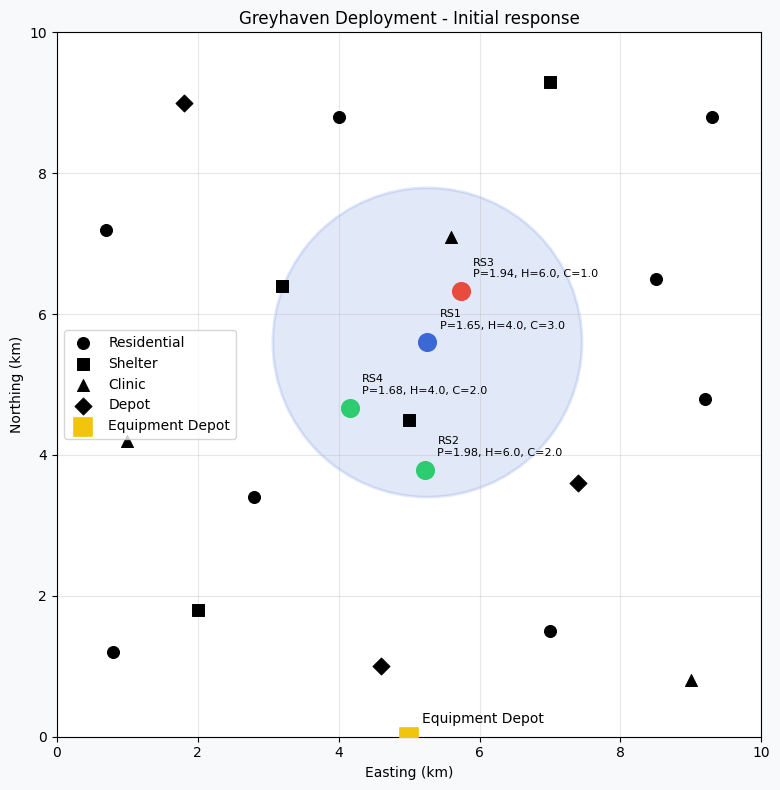


SPEA2 | Q=-0.8297, C=828.9836, E=474.2946


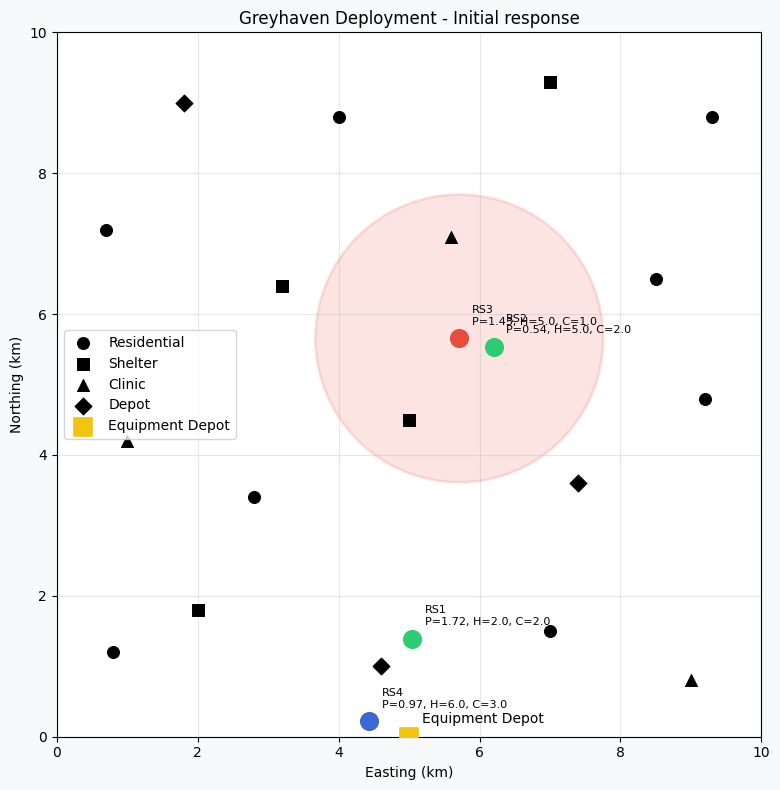

,Algorithm,Q,C,E,x0,y0,p0,h0,c0,z0,...,p2,h2,c2,z2,x3,y3,p3,h3,c3,z3
0,NSGA2,-0.728934,533.243945,515.695521,5.780096,9.844131,0.522559,2.0,1.0,0.0,...,1.822418,4.0,2.0,0.0,6.424574,4.701093,1.748188,3.0,1.0,1.0
1,NSGA3,-0.815066,652.060519,504.532423,5.260372,5.596973,1.646026,4.0,3.0,1.0,...,1.942914,6.0,1.0,0.0,4.157940,4.668994,1.677233,4.0,2.0,0.0
2,SPEA2,-0.829732,828.983575,474.294565,5.042132,1.392455,1.724697,2.0,2.0,0.0,...,1.430325,5.0,1.0,1.0,4.435510,0.217554,0.971456,6.0,3.0,0.0


In [179]:
best_table = best_solutions(all_results, "Initial response")
display(best_table)
best_table.to_excel(f"results/C_best_solutions_initial_response.xlsx", index=False)

## Print All pymoo Optimization Algorithm names

In [4]:
print("pymoo version:")

print(pymoo.__version__)

print("\nAvailable multi-objective algorithm classes:\n")

for _, module_name, _ in pkgutil.iter_modules(moo.__path__):

    module = importlib.import_module(
        f"pymoo.algorithms.moo.{module_name}"
    )

    for name, obj in inspect.getmembers(module, inspect.isclass):

        if (
            obj.__module__ == module.__name__
            and name.isupper()
        ):
            print(f"{name:20} | {module_name}")


pymoo version:
0.6.2

Available multi-objective algorithm classes:

AGEMOEA              | age
AGEMOEA2             | age2
CMOPSO               | cmopso
CTAEA                | ctaea
DNSGA2               | dnsga2
GDE3                 | gde3
GDE32NN              | gde3
GDE3MNN              | gde3
GDE3PCD              | gde3
KGB                  | kgb
MOEAD                | moead
MOPSO_CD             | mopso_cd
NSDE                 | nsde
NSDER                | nsder
NSGA2                | nsga2
NSGA3                | nsga3
PINSGA2              | pinsga2
RNSGA2               | rnsga2
RNSGA3               | rnsga3
RVEA                 | rvea
SMSEMOA              | sms
SPEA2                | spea2
UNSGA3               | unsga3
